# Weather Consistency's Relationship to Mental Health in the US

# Permissions

Place an `X` in the appropriate bracket below to specify if you would like your group's project to be made available to the public. (Note that student names will be included (but PIDs will be scraped from any groups who include their PIDs).

* [  ] YES - make available
* [ X ] NO - keep private

# Names

- Preity Singh
- Lavin Ma
- Katie Ngo
- Thatcher Eames
- Krrish Jain

# Abstract

This project investigates whether seasonal temperature variability plays a role in the differences in mental health outcomes across U.S. cities. We assessed the relationship between flunctuations in daily temperatures and rates of mental distress in 2021 and 2022.

Throughout our analysis, we combined weather data from the Carnegie Mellon Climate Database with CDC's PLACES model-based mental health estimates. This was done through computing each city's average temperature, temperature standard deviation, and its range. Next, we visualized and incorporated our interpretations based on the patterns we discovered.

Our analysis found no clear statistical relationship between temperature variability and mental distress. A linear regression model using 2021 weather data to predict 2022 mental health outcomes explained less than 2% of the variance. This shows that temperature variation alone is not a strong predictor of mental well-being and happiness. Our findings highlight that mental health is highly complex; there are a wide range of structural and social determinants that influence mental health.

# Research Question

#### Does seasonal temperature varibiability, which will be measured by the standard deviation from average daily temperatures, help explain differences in location-based mental health metrics, measured by the CDC in the years 2021 and 2022?
Our research will attempt to minimize the influence of confounding variables by accounting for other  impactful statistics on mental health.

#### Subquestion:
Which factor more closely aligns with mental health outcomes: average temperature or temperature variability?

## Background and Prior Work


The relationship between weather and human well-being has been a topic of interest in environmental research for years, with strong connections to psychological studies. Numerous studies have shown that weather conditions such as sunny days tend to improve mood, while rainy days can increase feelings of sadness. Although these findings are valuable, weather is a complex phenomenon that encompasses a wide range of factors, making it challenging to grasp its direct effects on human well-being. To address this, our research aims to investigate the role of temperature variability within a single day. We will examine whether the fluctuation between daytime high and nighttime low temperatures has a profound effect mental health, as well as a city’s overall happiness. By focusing on temperature variability rather than climate trends, we can more accurately identify patterns that reveal how weather affects mental distress.

Past research has utilized long-term average temperatures to draw conclusions about the impact of weather on happiness. For example, Rehdanz’s study of climate trends in 67 countries, using mean temperature and precipitation in the hottest and coldest months, found that higher temperatures during the coldest month were associated with greater happiness.<a name="cite_ref-1"></a>[<sup>1</sup>](#cite_note-1) Another study by Tsutsui found that happiness was highest at a maximum temperature of 13.9 Celsius.<a name="cite_ref-2"></a>[<sup>2</sup>](#cite_note-2) However, the results also indicated that although temperature influences people’s happiness, there is considerable variation in their responses. Few studies have explored how day-to-day weather changes, such as shifts between extreme and low temperatures, affect individuals’ happiness. A notable exception is research by Lucas and Lawless, which analyzed data from 1 million Americans over five years, combining different daily weather variables with life satisfaction ratings. They concluded that there was no significant correlation between temperature and life satisfaction judgments.<a name="cite_ref-3"></a>[<sup>3</sup>](#cite_note-3)

**Our work narrows the focus to temperature variability and its relationship with rates of mental distress. Past work has focused on average temperatures and its relationship to happiness. Does the overall consistency of the weather, consistently hot or cold rather than prone to large fluctutions throughout the year, correlate with overall happiness? Does stability bring increase mental well-being?**

This question connects to a broader idea in psychology: the more uncontrolled factors in your life, the more likely they are to impact your mental health. Weather, as an external and often unpredictable force, may function as one of these factors. If we view stability as a source of comfort and predictability, then cities with more stable weather patterns might foster a greater sense of peace and happiness among residents. Constant change, even in something as mundane as temperature, could contribute to stress or discomfort. Does greater stability in the environment support mental well-being? This is the central question our project seeks to explore.

1. <a name="cite_note-1"></a> [^](#cite_ref-1) Rehdanz, Katrin (8 Dec 2004) Climate and Happiness. *Ecological Economics*. https://www.sciencedirect.com/science/article/pii/S0921800904002940 
2. <a name="cite_note-2"></a> [^](#cite_ref-2) Tsutsui, Yoshiro (1 Jan 2013) Weather and Individual Happiness. *Weather, Climate, and Society*. https://journals.ametsoc.org/view/journals/wcas/5/1/wcas-d-11-00052_1.xml 
3. <a name="cite_note-3"></a> [^](#cite_ref-3) Lucas, Richard E. and Lawless, Nicole M. (1 May 2014) Does Life Seem Better on a Sunny Day? *National Library of Medicine*. https://pmc.ncbi.nlm.nih.gov/articles/PMC3695376/

# Hypothesis



Our hypothesis is that cities with greater seasonal temperature variability, measured by the standard deviation of daily temperatures, will result in higher rates of depression and an increase in mental distress among adults.
The thought process here centers on environmental stability, where predictable and consistent weather patterns play a role in psychological stability. Conversely, extreme shifts in temperature reduce our sense of control, disrupt daily routines, and raise stress levels, all of which negatively impact mental health.

# Data

## Data overview

For each dataset include the following information
- Dataset #1
  - Dataset Name: **CDC Mental Health Data**
  - Link to the dataset: https://www.cdc.gov/places/about/index.html
  - Number of observations: 3,592
  - Number of variables: 7
  - Description: The key variables include the location, population count and percentage, and health measure names. We will filter out the two measures: “Depression among adults” and “Frequent mental distress among adults” for our analysis of the years 2021 and 2022.
- Dataset #2
  - Dataset Name: **Carnegie Mellon Temperature and Precipitation Data**
  - Link to the dataset: https://kilthub.cmu.edu/articles/dataset/Compiled_daily_temperature_and_precipitation_data_for_the_U_S_cities/7890488
  - Number of observations: 238,710
  - Number of variables: 8
  - Description: This dataset contains daily weather data for each day starting earlier than year 1900 within 210 U.S. cities. The key variables in this dataset with their respective city names are max/min temperature in Fahrenheit (float), precipitation in inches (float), and data (string). We will use these metrics for daily climate variability by filtering for the years 2021 and 2022, extracting the appropriate month and day, and removing unnecessary columns.

Combining the Datasets: In order to analyze the relationship between temperature variability and mental health outcomes, cities appearing in both datasets were selected for analysis. We matched city name and year to calculate temperature variability using the standard deviation of daily temperatures. Using comparative analysis, we integrated the data with mental health statistics to draw meaningful conclusions.

## CDC Mental Health Data

In [2]:
import numpy as np
import pandas as pd
import sklearn as sk
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
us_health_data = pd.read_csv('CDC_Place_Health_Data.csv')
print(us_health_data.shape)
print(us_health_data['Measure'].unique())
print(us_health_data['Year'].unique())
print(len(us_health_data['LocationName'].unique()))

(2274860, 22)
['High blood pressure among adults'
 'High cholesterol among adults who have ever been screened'
 'Taking medicine to control high blood pressure among adults with high blood pressure'
 'Cholesterol screening among adults' 'Cognitive disability among adults'
 'Any disability among adults' 'Hearing disability among adults'
 'Independent living disability among adults'
 'Mobility disability among adults' 'Self-care disability among adults'
 'Vision disability among adults' 'Arthritis among adults'
 'Cancer (non-skin) or melanoma among adults'
 'Current asthma among adults' 'Coronary heart disease among adults'
 'Chronic obstructive pulmonary disease among adults'
 'Depression among adults' 'Diagnosed diabetes among adults'
 'Obesity among adults' 'Stroke among adults'
 'All teeth lost among adults aged >=65 years'
 'Fair or poor self-rated health status among adults'
 'Frequent mental distress among adults'
 'Frequent physical distress among adults'
 'Current lack of health

In [4]:
mental_health_data_unclean = us_health_data.loc[us_health_data['Measure'].isin(['Frequent mental distress among adults', 'Depression among adults'])]

## Carnagie Mellon Temperature and Percipitation Data

In [5]:
# Each city has its data in a seperate DataFrame named by an id number. The name & data of each city corresponding to the id is tracked in the dataframe below
ctd_key = pd.read_csv('Historical Weather Data/city_info.csv')

In [6]:
city_temperature_data_unclean = pd.DataFrame()

for ind in ctd_key.index:
    city_name = ctd_key.iloc[ind,1]
    city_id = ctd_key.iloc[ind,2]
    csv_file_name = 'Historical Weather Data/' + city_id + '.csv'
    city_data_frame = pd.read_csv(csv_file_name)
    city_data_frame.insert(loc=0, column='City', value = city_name)
    city_temperature_data_unclean = pd.concat([city_temperature_data_unclean, city_data_frame])

In [7]:
cities_in_weather = city_temperature_data_unclean['City'].unique()
cities_in_health = mental_health_data_unclean['LocationName'].unique()

cities_in_common = np.intersect1d(cities_in_weather, cities_in_health)

In [8]:
mental_health_data_unclean = us_health_data.loc[us_health_data['Measure'].isin(['Frequent mental distress among adults', 'Depression among adults'])]
mental_health_data_unclean

,Year,StateAbbr,StateDesc,LocationName,DataSource,Category,Measure,Data_Value_Unit,Data_Value_Type,Data_Value,...,Low_Confidence_Limit,High_Confidence_Limit,TotalPop18plus,TotalPopulation,Geolocation,LocationID,CategoryID,MeasureId,DataValueTypeID,Short_Question_Text
18496,2022,AL,Alabama,Standing Rock,BRFSS,Health Outcomes,Depression among adults,%,Age-adjusted prevalence,29.7,...,25.7,34.1,112,132,POINT (-85.2398494 33.0856897),172720,HLTHOUT,DEPRESSION,AgeAdjPrv,Depression
18497,2022,AL,Alabama,Lisman,BRFSS,Health Outcomes,Depression among adults,%,Age-adjusted prevalence,21.0,...,17.6,24.6,348,427,POINT (-88.284092 32.1717293),143384,HLTHOUT,DEPRESSION,AgeAdjPrv,Depression
18498,2022,AL,Alabama,Coats Bend,BRFSS,Health Outcomes,Depression among adults,%,Age-adjusted prevalence,28.4,...,24.7,32.4,1024,1318,POINT (-85.8746016 34.0732735),116080,HLTHOUT,DEPRESSION,AgeAdjPrv,Depression
18499,2022,AL,Alabama,Rehobeth,BRFSS,Health Outcomes,Depression among adults,%,Age-adjusted prevalence,28.9,...,24.9,33.1,1302,1791,POINT (-85.4396074 31.1245066),164152,HLTHOUT,DEPRESSION,AgeAdjPrv,Depression
18500,2022,AL,Alabama,Deer Park,BRFSS,Health Outcomes,Depression among adults,%,Age-adjusted prevalence,24.9,...,21.2,29.2,100,141,POINT (-88.3280229 31.2183694),120152,HLTHOUT,DEPRESSION,AgeAdjPrv,Depression
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2268939,2022,WY,Wyoming,Arapahoe,BRFSS,Health Status,Frequent mental distress among adults,%,Crude prevalence,22.8,...,20.6,25.1,1070,1612,POINT (-108.4527296 42.992567),5603000,HLTHSTAT,MHLTH,CrdPrv,Frequent Mental Distress
2268940,2022,WY,Wyoming,East Thermopolis,BRFSS,Health Status,Frequent mental distress among adults,%,Crude prevalence,13.4,...,11.9,15.0,196,229,POINT (-108.1978826 43.6440937),5622720,HLTHSTAT,MHLTH,CrdPrv,Frequent Mental Distress
2268941,2022,WY,Wyoming,La Barge,BRFSS,Health Status,Frequent mental distress among adults,%,Crude prevalence,14.9,...,13.3,16.6,295,394,POINT (-110.1972028 42.2607794),5643455,HLTHSTAT,MHLTH,CrdPrv,Frequent Mental Distress
2268942,2022,WY,Wyoming,Eden,BRFSS,Health Status,Frequent mental distress among adults,%,Crude prevalence,14.7,...,13.1,16.4,183,235,POINT (-109.4391518 42.0601649),5623010,HLTHSTAT,MHLTH,CrdPrv,Frequent Mental Distress


In [9]:
mental_health_data_unclean = mental_health_data_unclean.loc[mental_health_data_unclean['DataValueTypeID'] == 'AgeAdjPrv']
mental_health_data_unclean

,Year,StateAbbr,StateDesc,LocationName,DataSource,Category,Measure,Data_Value_Unit,Data_Value_Type,Data_Value,...,Low_Confidence_Limit,High_Confidence_Limit,TotalPop18plus,TotalPopulation,Geolocation,LocationID,CategoryID,MeasureId,DataValueTypeID,Short_Question_Text
18496,2022,AL,Alabama,Standing Rock,BRFSS,Health Outcomes,Depression among adults,%,Age-adjusted prevalence,29.7,...,25.7,34.1,112,132,POINT (-85.2398494 33.0856897),172720,HLTHOUT,DEPRESSION,AgeAdjPrv,Depression
18497,2022,AL,Alabama,Lisman,BRFSS,Health Outcomes,Depression among adults,%,Age-adjusted prevalence,21.0,...,17.6,24.6,348,427,POINT (-88.284092 32.1717293),143384,HLTHOUT,DEPRESSION,AgeAdjPrv,Depression
18498,2022,AL,Alabama,Coats Bend,BRFSS,Health Outcomes,Depression among adults,%,Age-adjusted prevalence,28.4,...,24.7,32.4,1024,1318,POINT (-85.8746016 34.0732735),116080,HLTHOUT,DEPRESSION,AgeAdjPrv,Depression
18499,2022,AL,Alabama,Rehobeth,BRFSS,Health Outcomes,Depression among adults,%,Age-adjusted prevalence,28.9,...,24.9,33.1,1302,1791,POINT (-85.4396074 31.1245066),164152,HLTHOUT,DEPRESSION,AgeAdjPrv,Depression
18500,2022,AL,Alabama,Deer Park,BRFSS,Health Outcomes,Depression among adults,%,Age-adjusted prevalence,24.9,...,21.2,29.2,100,141,POINT (-88.3280229 31.2183694),120152,HLTHOUT,DEPRESSION,AgeAdjPrv,Depression
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2268765,2022,WY,Wyoming,Elk Mountain,BRFSS,Health Status,Frequent mental distress among adults,%,Age-adjusted prevalence,17.3,...,15.4,19.3,125,150,POINT (-106.4135012 41.6882978),5624025,HLTHSTAT,MHLTH,AgeAdjPrv,Frequent Mental Distress
2268766,2022,WY,Wyoming,Douglas,BRFSS,Health Status,Frequent mental distress among adults,%,Age-adjusted prevalence,17.0,...,15.3,18.8,4686,6386,POINT (-105.3974188 42.7538087),5621125,HLTHSTAT,MHLTH,AgeAdjPrv,Frequent Mental Distress
2268767,2022,WY,Wyoming,Dubois,BRFSS,Health Status,Frequent mental distress among adults,%,Age-adjusted prevalence,16.6,...,14.8,18.5,756,911,POINT (-109.6476285 43.545964),5621415,HLTHSTAT,MHLTH,AgeAdjPrv,Frequent Mental Distress
2268768,2022,WY,Wyoming,Burns,BRFSS,Health Status,Frequent mental distress among adults,%,Age-adjusted prevalence,16.5,...,14.9,18.2,257,356,POINT (-104.3590349 41.1908709),5611265,HLTHSTAT,MHLTH,AgeAdjPrv,Frequent Mental Distress


## Carnagie Mellon Temperature and Percipitation Data

In [10]:
# Each city has its data in a seperate DataFrame named by an id number. The name & data of each city corresponding to the id is tracked in the dataframe below
ctd_key = pd.read_csv('Historical Weather Data/city_info.csv')

In [11]:
us_state_to_abbrev = {
    "Alabama": "AL",
    "Alaska": "AK",
    "Arizona": "AZ",
    "Arkansas": "AR",
    "California": "CA",
    "Colorado": "CO",
    "Connecticut": "CT",
    "Delaware": "DE",
    "Florida": "FL",
    "Georgia": "GA",
    "Hawaii": "HI",
    "Idaho": "ID",
    "Illinois": "IL",
    "Indiana": "IN",
    "Iowa": "IA",
    "Kansas": "KS",
    "Kentucky": "KY",
    "Louisiana": "LA",
    "Maine": "ME",
    "Maryland": "MD",
    "Massachusetts": "MA",
    "Michigan": "MI",
    "Minnesota": "MN",
    "Mississippi": "MS",
    "Missouri": "MO",
    "Montana": "MT",
    "Nebraska": "NE",
    "Nevada": "NV",
    "New Hampshire": "NH",
    "New Jersey": "NJ",
    "New Mexico": "NM",
    "New York": "NY",
    "North Carolina": "NC",
    "North Dakota": "ND",
    "Ohio": "OH",
    "Oklahoma": "OK",
    "Oregon": "OR",
    "Pennsylvania": "PA",
    "Rhode Island": "RI",
    "South Carolina": "SC",
    "South Dakota": "SD",
    "Tennessee": "TN",
    "Texas": "TX",
    "Utah": "UT",
    "Vermont": "VT",
    "Virginia": "VA",
    "Washington": "WA",
    "West Virginia": "WV",
    "Wisconsin": "WI",
    "Wyoming": "WY",
    "District of Columbia": "DC",
}

us_state_abbrev = [
    "AL",
    "AK",
    "AZ",
    "AR",
    "CA",
    "CO",
    "CT",
    "DE",
    "FL",
    "GA",
    "HI",
    "ID",
    "IL",
    "IN",
    "IA",
    "KS",
    "KY",
    "LA",
    "ME",
    "MD",
    "MA",
    "MI",
    "MN",
    "MS",
    "MO",
    "MT",
    "NE",
    "NV",
    "NH",
    "NJ",
    "NM",
    "NY",
    "NC",
    "ND",
    "OH",
    "OK",
    "OR",
    "PA",
    "RI",
    "SC",
    "SD",
    "TN",
    "TX",
    "UT",
    "VT",
    "VA",
    "WA",
    "WV",
    "WI",
    "WY",
    "DC",
]

In [12]:
import geopy as gp
geolocator = gp.geocoders.Nominatim(user_agent='UCSD_Data_Science_Project')

def find_state(latitude, longitude):
    lat = str(latitude)
    long = str(longitude)
    
    try:
        location = geolocator.geocode(lat+","+long)
    except(gp.exc.GeocoderTimedOut):
        return('NA')
    
    address = location.address

    address_array = address.split(", ")

    for address_item in address_array:
        if address_item in us_state_to_abbrev:
            #print(us_state_to_abbrev[address_item])
            return us_state_to_abbrev[address_item]


In [13]:
ctd_key['State'] = ctd_key.apply(lambda row: find_state(row['Lat'], row['Lon']), axis=1)
ctd_key

,Unnamed: 0,Name,ID,Lat,Lon,Stn.Name,Stn.stDate,Stn.edDate,State
0,1,Lander,USW00024021,42.8153,-108.7261,LANDER WBO,1892-01-01,1946-05-28,WY
1,2,Lander,USW00024021,42.8153,-108.7261,LANDER HUNT FIELD,1946-05-29,2023-12-31,NA
2,3,Cheyenne,USW00024018,41.1519,-104.8061,CHEYENNE WBO,1871-01-01,1935-08-31,WY
3,4,Cheyenne,USW00024018,41.1519,-104.8061,CHEYENNE MUNICIPAL ARPT,1935-09-01,2023-12-31,WY
4,5,Wausau,USW00014897,44.9258,-89.6256,Wausau Record Herald,1896-01-01,1941-12-31,WI
...,...,...,...,...,...,...,...,...,...
456,457,Huntsville,USW00003856,34.6439,-86.7861,HUNTSVILLE,1937-01-01,1954-07-14,AL
457,458,Huntsville,USW00003856,34.6439,-86.7861,MADISON,1954-07-15,1958-08-31,AL
458,459,Huntsville,USW00003856,34.6439,-86.7861,HUNTSVILLE,1958-09-01,2023-12-31,AL
459,460,Birmingham,USW00013876,33.5656,-86.7450,BIRMINGHAM,1896-01-01,1903-12-31,AL


In [14]:
city_temperature_data_unclean = pd.DataFrame()

for ind in ctd_key.index:
    city_name = ctd_key.iloc[ind,1]
    city_id = ctd_key.iloc[ind,2]
    city_state = ctd_key.loc[ind,'State']
    csv_file_name = 'Historical Weather Data/' + city_id + '.csv'
    city_data_frame = pd.read_csv(csv_file_name)
    city_data_frame.insert(loc=0, column='City', value=city_name)
    city_data_frame.insert(loc=1, column='State', value=city_state)
    city_temperature_data_unclean = pd.concat([city_temperature_data_unclean, city_data_frame])

In [15]:
def get_location(city_name, state_abv):
    for state in us_state_abbrev:
        city_name = city_name.replace(state, "")
    city_name = city_name.lower()
    city_name = city_name.strip()
    city_name = city_name.replace(" ", "")
    return city_name + state_abv

In [16]:
city_temperature_data_unclean['Location'] = city_temperature_data_unclean.apply(lambda row: get_location(row['City'], row['State']), axis=1)
city_temperature_data_unclean

,City,State,Unnamed: 0,Date,tmax,tmin,prcp,Location
0,Lander,WY,1,1892-01-01,32.0,-5.0,0.00,landerWY
1,Lander,WY,2,1892-01-02,38.0,2.0,0.00,landerWY
2,Lander,WY,3,1892-01-03,50.0,16.0,0.00,landerWY
3,Lander,WY,4,1892-01-04,46.0,32.0,0.00,landerWY
4,Lander,WY,5,1892-01-05,21.0,10.0,0.16,landerWY
...,...,...,...,...,...,...,...,...
46746,Birmingham,AL,46747,2023-12-27,57.0,34.0,0.00,birminghamAL
46747,Birmingham,AL,46748,2023-12-28,48.9,33.1,0.00,birminghamAL
46748,Birmingham,AL,46749,2023-12-29,46.0,37.0,0.00,birminghamAL
46749,Birmingham,AL,46750,2023-12-30,41.0,31.1,0.01,birminghamAL


In [17]:
mental_health_data_unclean['Location'] = mental_health_data_unclean.apply(lambda row: get_location(row["LocationName"], row["StateAbbr"]), axis=1)
mental_health_data_unclean

/var/folders/p2/9fszjsdn5yx_pn2c1brj7kfc0000gn/T/ipykernel_17733/4100702807.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mental_health_data_unclean['Location'] = mental_health_data_unclean.apply(lambda row: get_location(row["LocationName"], row["StateAbbr"]), axis=1)


,Year,StateAbbr,StateDesc,LocationName,DataSource,Category,Measure,Data_Value_Unit,Data_Value_Type,Data_Value,...,High_Confidence_Limit,TotalPop18plus,TotalPopulation,Geolocation,LocationID,CategoryID,MeasureId,DataValueTypeID,Short_Question_Text,Location
18496,2022,AL,Alabama,Standing Rock,BRFSS,Health Outcomes,Depression among adults,%,Age-adjusted prevalence,29.7,...,34.1,112,132,POINT (-85.2398494 33.0856897),172720,HLTHOUT,DEPRESSION,AgeAdjPrv,Depression,standingrockAL
18497,2022,AL,Alabama,Lisman,BRFSS,Health Outcomes,Depression among adults,%,Age-adjusted prevalence,21.0,...,24.6,348,427,POINT (-88.284092 32.1717293),143384,HLTHOUT,DEPRESSION,AgeAdjPrv,Depression,lismanAL
18498,2022,AL,Alabama,Coats Bend,BRFSS,Health Outcomes,Depression among adults,%,Age-adjusted prevalence,28.4,...,32.4,1024,1318,POINT (-85.8746016 34.0732735),116080,HLTHOUT,DEPRESSION,AgeAdjPrv,Depression,coatsbendAL
18499,2022,AL,Alabama,Rehobeth,BRFSS,Health Outcomes,Depression among adults,%,Age-adjusted prevalence,28.9,...,33.1,1302,1791,POINT (-85.4396074 31.1245066),164152,HLTHOUT,DEPRESSION,AgeAdjPrv,Depression,rehobethAL
18500,2022,AL,Alabama,Deer Park,BRFSS,Health Outcomes,Depression among adults,%,Age-adjusted prevalence,24.9,...,29.2,100,141,POINT (-88.3280229 31.2183694),120152,HLTHOUT,DEPRESSION,AgeAdjPrv,Depression,deerparkAL
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2268765,2022,WY,Wyoming,Elk Mountain,BRFSS,Health Status,Frequent mental distress among adults,%,Age-adjusted prevalence,17.3,...,19.3,125,150,POINT (-106.4135012 41.6882978),5624025,HLTHSTAT,MHLTH,AgeAdjPrv,Frequent Mental Distress,elkmountainWY
2268766,2022,WY,Wyoming,Douglas,BRFSS,Health Status,Frequent mental distress among adults,%,Age-adjusted prevalence,17.0,...,18.8,4686,6386,POINT (-105.3974188 42.7538087),5621125,HLTHSTAT,MHLTH,AgeAdjPrv,Frequent Mental Distress,douglasWY
2268767,2022,WY,Wyoming,Dubois,BRFSS,Health Status,Frequent mental distress among adults,%,Age-adjusted prevalence,16.6,...,18.5,756,911,POINT (-109.6476285 43.545964),5621415,HLTHSTAT,MHLTH,AgeAdjPrv,Frequent Mental Distress,duboisWY
2268768,2022,WY,Wyoming,Burns,BRFSS,Health Status,Frequent mental distress among adults,%,Age-adjusted prevalence,16.5,...,18.2,257,356,POINT (-104.3590349 41.1908709),5611265,HLTHSTAT,MHLTH,AgeAdjPrv,Frequent Mental Distress,burnsWY


In [18]:
cities_in_weather = city_temperature_data_unclean['Location'].unique()
cities_in_health = mental_health_data_unclean['Location'].unique()

cities_in_common = np.intersect1d(cities_in_weather, cities_in_health)

print(cities_in_common.size)

181


In [19]:
mental_health_data = mental_health_data_unclean[mental_health_data_unclean['Location'].isin(cities_in_common)]
mental_health_data = mental_health_data.reset_index(drop=True)
print(mental_health_data.columns)
mental_health_data

Index(['Year', 'StateAbbr', 'StateDesc', 'LocationName', 'DataSource',
       'Category', 'Measure', 'Data_Value_Unit', 'Data_Value_Type',
       'Data_Value', 'Data_Value_Footnote_Symbol', 'Data_Value_Footnote',
       'Low_Confidence_Limit', 'High_Confidence_Limit', 'TotalPop18plus',
       'TotalPopulation', 'Geolocation', 'LocationID', 'CategoryID',
       'MeasureId', 'DataValueTypeID', 'Short_Question_Text', 'Location'],
      dtype='object')


,Year,StateAbbr,StateDesc,LocationName,DataSource,Category,Measure,Data_Value_Unit,Data_Value_Type,Data_Value,...,High_Confidence_Limit,TotalPop18plus,TotalPopulation,Geolocation,LocationID,CategoryID,MeasureId,DataValueTypeID,Short_Question_Text,Location
0,2022,AL,Alabama,Birmingham,BRFSS,Health Outcomes,Depression among adults,%,Age-adjusted prevalence,22.7,...,25.7,163166,200733,POINT (-86.7970356 33.5271744),107000,HLTHOUT,DEPRESSION,AgeAdjPrv,Depression,birminghamAL
1,2022,AL,Alabama,Muscle Shoals,BRFSS,Health Outcomes,Depression among adults,%,Age-adjusted prevalence,25.6,...,29.6,12488,16275,POINT (-87.6337614 34.7431698),153016,HLTHOUT,DEPRESSION,AgeAdjPrv,Depression,muscleshoalsAL
2,2022,AL,Alabama,Mobile,BRFSS,Health Outcomes,Depression among adults,%,Age-adjusted prevalence,23.2,...,26.4,146022,187041,POINT (-88.1002261 30.668426),150000,HLTHOUT,DEPRESSION,AgeAdjPrv,Depression,mobileAL
3,2022,AL,Alabama,Montgomery,BRFSS,Health Outcomes,Depression among adults,%,Age-adjusted prevalence,21.9,...,25.0,155079,200603,POINT (-86.2673072 32.3485029),151000,HLTHOUT,DEPRESSION,AgeAdjPrv,Depression,montgomeryAL
4,2022,AL,Alabama,Huntsville,BRFSS,Health Outcomes,Depression among adults,%,Age-adjusted prevalence,23.4,...,26.9,172302,215006,POINT (-86.5325989 34.7822752),137000,HLTHOUT,DEPRESSION,AgeAdjPrv,Depression,huntsvilleAL
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
357,2022,WI,Wisconsin,Hayward,BRFSS,Health Status,Frequent mental distress among adults,%,Age-adjusted prevalence,18.1,...,20.0,1986,2533,POINT (-91.4834356 46.0088847),5533450,HLTHSTAT,MHLTH,AgeAdjPrv,Frequent Mental Distress,haywardWI
358,2022,WY,Wyoming,Cheyenne,BRFSS,Health Outcomes,Depression among adults,%,Age-adjusted prevalence,21.9,...,24.7,50353,65132,POINT (-104.7907492 41.1352586),5613900,HLTHOUT,DEPRESSION,AgeAdjPrv,Depression,cheyenneWY
359,2022,WY,Wyoming,Lander,BRFSS,Health Outcomes,Depression among adults,%,Age-adjusted prevalence,22.0,...,25.5,5786,7546,POINT (-108.7598936 42.8312761),5644760,HLTHOUT,DEPRESSION,AgeAdjPrv,Depression,landerWY
360,2022,WY,Wyoming,Lander,BRFSS,Health Status,Frequent mental distress among adults,%,Age-adjusted prevalence,16.6,...,18.4,5786,7546,POINT (-108.7598936 42.8312761),5644760,HLTHSTAT,MHLTH,AgeAdjPrv,Frequent Mental Distress,landerWY


In [20]:
mental_health_data = mental_health_data[['Year', 'StateAbbr', 'LocationName', 'Measure', 'Data_Value', 'TotalPop18plus', 'TotalPopulation', 'Location']]
mental_health_data.columns = ['year', 'state', 'city name', 'measure', 'percentage', 'population over 18', 'population', 'location']
mental_health_data

,year,state,city name,measure,percentage,population over 18,population,location
0,2022,AL,Birmingham,Depression among adults,22.7,163166,200733,birminghamAL
1,2022,AL,Muscle Shoals,Depression among adults,25.6,12488,16275,muscleshoalsAL
2,2022,AL,Mobile,Depression among adults,23.2,146022,187041,mobileAL
3,2022,AL,Montgomery,Depression among adults,21.9,155079,200603,montgomeryAL
4,2022,AL,Huntsville,Depression among adults,23.4,172302,215006,huntsvilleAL
...,...,...,...,...,...,...,...,...
357,2022,WI,Hayward,Frequent mental distress among adults,18.1,1986,2533,haywardWI
358,2022,WY,Cheyenne,Depression among adults,21.9,50353,65132,cheyenneWY
359,2022,WY,Lander,Depression among adults,22.0,5786,7546,landerWY
360,2022,WY,Lander,Frequent mental distress among adults,16.6,5786,7546,landerWY


In [21]:
city_temperature_data = city_temperature_data_unclean[city_temperature_data_unclean['Date'].str.contains('2021|2022', case=False, na=False)]
city_temperature_data = city_temperature_data[city_temperature_data['Location'].isin(cities_in_common)]
city_temperature_data = city_temperature_data.drop('Unnamed: 0', axis=1)
city_temperature_data = city_temperature_data.reset_index(drop=True)
city_temperature_data.columns = ['city name', 'state', 'date', 'temperature max', 'temperature min', 'precipitation', 'location']
city_temperature_data

,city name,state,date,temperature max,temperature min,precipitation,location
0,Lander,WY,2021-01-01,33.1,11.1,0.00,landerWY
1,Lander,WY,2021-01-02,41.0,9.1,0.00,landerWY
2,Lander,WY,2021-01-03,43.0,15.3,0.00,landerWY
3,Lander,WY,2021-01-04,39.0,17.2,0.00,landerWY
4,Lander,WY,2021-01-05,37.0,21.2,0.00,landerWY
...,...,...,...,...,...,...,...
257685,Birmingham,AL,2022-12-27,53.1,27.0,0.00,birminghamAL
257686,Birmingham,AL,2022-12-28,62.1,30.0,0.00,birminghamAL
257687,Birmingham,AL,2022-12-29,71.1,52.0,0.00,birminghamAL
257688,Birmingham,AL,2022-12-30,66.0,54.0,0.12,birminghamAL


In [22]:
def get_year(date_string):
    return int(date_string[0:4])

def get_month(date_string):
    return int(date_string[5:7])

def get_day(date_string):
    return int(date_string[8:10])

city_temperature_data['year'] = city_temperature_data['date'].apply(get_year)
city_temperature_data['month'] = city_temperature_data['date'].apply(get_month)
city_temperature_data['day'] = city_temperature_data['date'].apply(get_day)

city_temperature_data

,city name,state,date,temperature max,temperature min,precipitation,location,year,month,day
0,Lander,WY,2021-01-01,33.1,11.1,0.00,landerWY,2021,1,1
1,Lander,WY,2021-01-02,41.0,9.1,0.00,landerWY,2021,1,2
2,Lander,WY,2021-01-03,43.0,15.3,0.00,landerWY,2021,1,3
3,Lander,WY,2021-01-04,39.0,17.2,0.00,landerWY,2021,1,4
4,Lander,WY,2021-01-05,37.0,21.2,0.00,landerWY,2021,1,5
...,...,...,...,...,...,...,...,...,...,...
257685,Birmingham,AL,2022-12-27,53.1,27.0,0.00,birminghamAL,2022,12,27
257686,Birmingham,AL,2022-12-28,62.1,30.0,0.00,birminghamAL,2022,12,28
257687,Birmingham,AL,2022-12-29,71.1,52.0,0.00,birminghamAL,2022,12,29
257688,Birmingham,AL,2022-12-30,66.0,54.0,0.12,birminghamAL,2022,12,30


# Results

## Exploratory Data Analysis

Carry out whatever EDA you need to for your project.  Because every project will be different we can't really give you much of a template at this point. But please make sure you describe the what and why in text here as well as providing interpretation of results and context.

## 1 - Temperature

We will group the temperature data by city and year to calculate central tendency and variability. These metrics help us understand how consistent or extreme the weather was in each city.

**Steps:**
1. Group the temperature data by `city name` and `year`
2. Calculate the following statistics:
   - Mean of average daily temperatures
   - Standard deviation of average daily temperatures
   - Maximum and minimum temperature recorded that year
   - Annual temperature range (max - min)

In [23]:
# Compute daily average temperature
city_temperature_data['temperature avg'] = (
    city_temperature_data['temperature max'] + city_temperature_data['temperature min']
) / 2

In [34]:
# Group temp data by city and year to compute mean, std dev, and range
weather_summary = city_temperature_data.groupby(['location', 'year']).agg({
    'temperature avg': ['mean', 'std'],
    'temperature max': 'max',
    'temperature min': 'min'
}).reset_index()

# Flatten multi-level column names
weather_summary.columns = ['location', 'year', 'mean temp', 'std dev temp', 'max temp', 'min temp']

# Calculate temperature range
weather_summary['range temp'] = weather_summary['max temp'] - weather_summary['min temp']
weather_summary.head()

,location,year,mean temp,std dev temp,max temp,min temp,range temp
0,abileneTX,2021,66.208082,15.756189,104.0,-3.8,107.8
1,abileneTX,2022,67.699178,18.718866,109.9,10.0,99.9
2,aikenSC,2021,63.590642,13.966697,96.1,26.1,70.0
3,aikenSC,2022,65.713986,14.565285,102.0,10.0,92.0
4,akronOH,2021,54.067260,18.105282,93.0,3.2,89.8


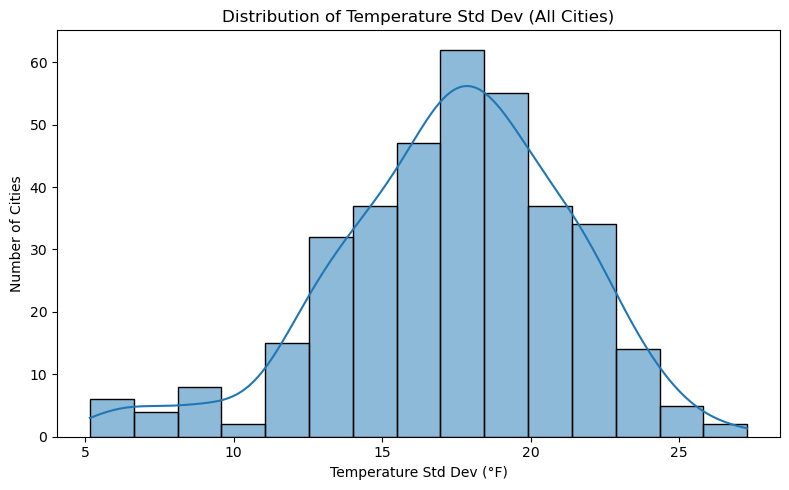

In [35]:
# Graph 1: Temperature Standard Deviation by City and Year
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(data=weather_summary, x='std dev temp', bins=15, kde=True)
plt.title('Distribution of Temperature Std Dev (All Cities)')
plt.xlabel('Temperature Std Dev (°F)')
plt.ylabel('Number of Cities')
plt.tight_layout()
plt.show()

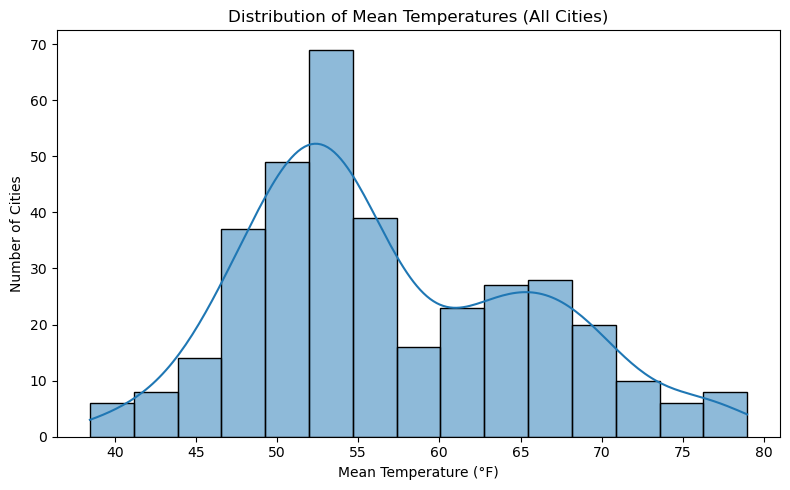

In [36]:
# Graph 2: Mean Temperature by City and Year
plt.figure(figsize=(8, 5))
sns.histplot(data=weather_summary, x='mean temp', bins=15, kde=True)
plt.title('Distribution of Mean Temperatures (All Cities)')
plt.xlabel('Mean Temperature (°F)')
plt.ylabel('Number of Cities')
plt.tight_layout()
plt.show()

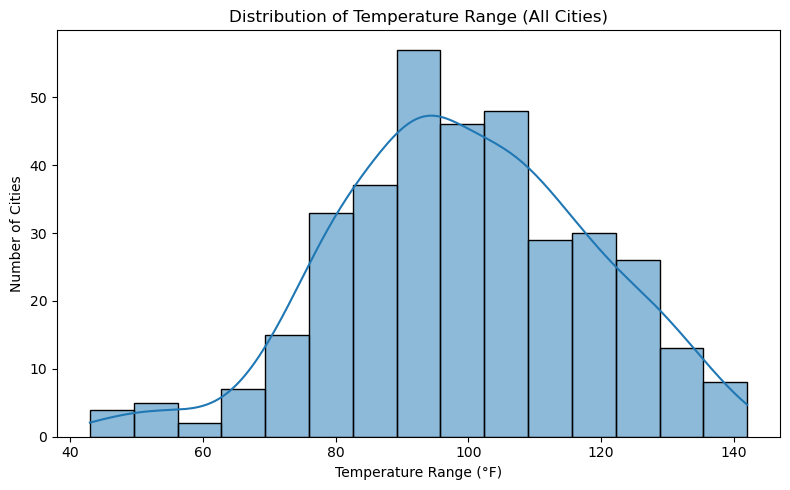

In [37]:
# Graph 3: Temperature Range by City and Year
plt.figure(figsize=(8, 5))
sns.histplot(data=weather_summary, x='range temp', bins=15, kde=True)
plt.title('Distribution of Temperature Range (All Cities)')
plt.xlabel('Temperature Range (°F)')
plt.ylabel('Number of Cities')
plt.tight_layout()
plt.show()

## 2 - Mental Health vs. Temperature

We will explore the relationship between mental health and temperature metrics across cities. Specifically, we will visualize how rates of frequent mental distress relate to key temperature statistics.

**Steps:**
1. Use the merged dataset `combined_df` which includes both mental health and temperature data.
2. Create scatterplots where:
   - x-axis = `mental distress %` (CDC-reported)
   - y-axis = `std dev temp`
   - hue = `year` (2021 or 2022)
3. Interpret visual trends: do cities with more temperature fluctuation report more mental distress?

### Graph - Mental Distress vs. Temperature Standard Deviation

In [38]:
mental_health_data
city_temperature_data

,city name,state,date,temperature max,temperature min,precipitation,location,year,month,day,temperature avg
0,Lander,WY,2021-01-01,33.1,11.1,0.00,landerWY,2021,1,1,22.10
1,Lander,WY,2021-01-02,41.0,9.1,0.00,landerWY,2021,1,2,25.05
2,Lander,WY,2021-01-03,43.0,15.3,0.00,landerWY,2021,1,3,29.15
3,Lander,WY,2021-01-04,39.0,17.2,0.00,landerWY,2021,1,4,28.10
4,Lander,WY,2021-01-05,37.0,21.2,0.00,landerWY,2021,1,5,29.10
...,...,...,...,...,...,...,...,...,...,...,...
257685,Birmingham,AL,2022-12-27,53.1,27.0,0.00,birminghamAL,2022,12,27,40.05
257686,Birmingham,AL,2022-12-28,62.1,30.0,0.00,birminghamAL,2022,12,28,46.05
257687,Birmingham,AL,2022-12-29,71.1,52.0,0.00,birminghamAL,2022,12,29,61.55
257688,Birmingham,AL,2022-12-30,66.0,54.0,0.12,birminghamAL,2022,12,30,60.00


In [39]:
# Uses pre-cleaned group mental health data
# Ensure the column names match the merge keys
mental_health_data = mental_health_data.rename(columns={
    'percentage': 'mental distress %',
    'LocationName': 'city name'  # Just in case it hasn't already been renamed
})

# Merge with weather summary data
combined_df = pd.merge(weather_summary, mental_health_data, on=['location', 'year'], how='inner')

# Check merge result
print("Combined data shape:", combined_df.shape)
print("Years in data:", combined_df['year'].unique())
combined_df.head()

Combined data shape: (362, 13)
Years in data: [2022]


,location,year,mean temp,std dev temp,max temp,min temp,range temp,state,city name,measure,mental distress %,population over 18,population
0,abileneTX,2022,67.699178,18.718866,109.9,10.0,99.9,TX,Abilene,Depression among adults,24.1,96412,125182
1,abileneTX,2022,67.699178,18.718866,109.9,10.0,99.9,TX,Abilene,Frequent mental distress among adults,19.4,96412,125182
2,aikenSC,2022,65.713986,14.565285,102.0,10.0,92.0,SC,Aiken,Depression among adults,21.5,26169,32025
3,aikenSC,2022,65.713986,14.565285,102.0,10.0,92.0,SC,Aiken,Frequent mental distress among adults,17.3,26169,32025
4,akronOH,2022,52.757945,19.134005,95.0,-5.1,100.1,OH,Akron,Depression among adults,26.7,149718,190469


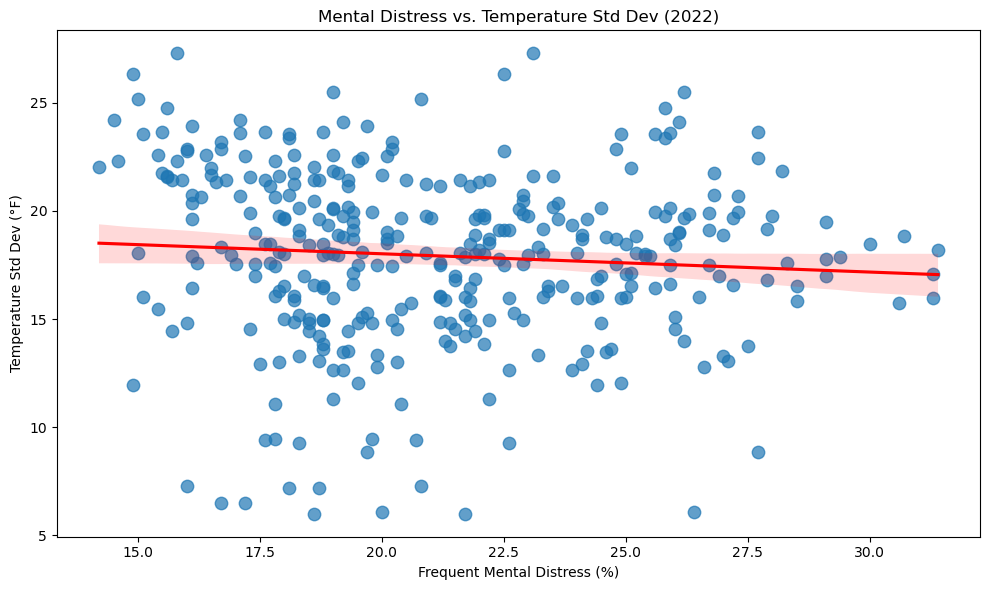

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

# Filter for 2022 data
combined_2022 = combined_df[combined_df['year'] == 2022]

# Compute Pearson correlation coefficient
r_small, _ = pearsonr(combined_2022['mental distress %'], combined_2022['std dev temp'])

# Plot
plt.figure(figsize=(10, 6))
sns.regplot(
    data=combined_2022,
    x='mental distress %',
    y='std dev temp',
    scatter_kws={'s': 80, 'alpha': 0.7},
    line_kws={'color': 'red'},
)

plt.title('Mental Distress vs. Temperature Std Dev (2022)')
plt.xlabel('Frequent Mental Distress (%)')
plt.ylabel('Temperature Std Dev (°F)')
plt.tight_layout()
plt.show()

### Interpretation of Mental Distress vs. Temperature Standard Deviation

This scatterplot explores whether cities with greater temperature variability also report higher rates of frequent mental distress.

**Visual Analysis:**
* The data points are widely scattered and form a fairly uniform, horizontal cloud.
* The regression line is nearly flat and slightly declining, but the red line’s slope is minimal, indicating almost no linear relationship.
* The computed Pearson correlation coefficient is NaN, which likely means your data includes missing values (NaNs) in one or both variables—this should be cleaned for reliable statistics.
* Even without the exact r, the visual pattern clearly suggests weak or no correlation

**Interpretation:**
This visualization provides no evidence of a meaningful linear relationship between temperature variability and frequent mental distress across U.S. cities in 2022. Despite the intuitive hypothesis that unstable weather might affect mood or mental health, this data suggests that temperature standard deviation is not a significant predictor of mental distress on its own. 

## 3 - Subset Visualizations: Exploring Cities by Population Size

To explore this relationship between temperature variability and frequent mental distress, some more, we decided to split the dataset by population size. Our reasoning is that larger cities and smaller cities might experience and report mental distress differently. Factors like access to healthcare, urban stressors, or community support systems can vary significantly by city size, potentially influencing how temperature affects mental health.

**Steps:**
1. Create a copy of `combined_df` to avoid altering the original dataset used in other analyses.
2. Merge in `population` data from `mental_health_data`, using `city name` and `year` as keys.
3. Calculate the **median population** and divide the dataset into two groups:
   - **Larger cities**: population ≥ median
   - **Smaller cities**: population < median
4. Create separate scatterplots for each group, comparing:
   - x-axis = `mental distress %`
   - y-axis = `std dev temp`
   - hue = `year`

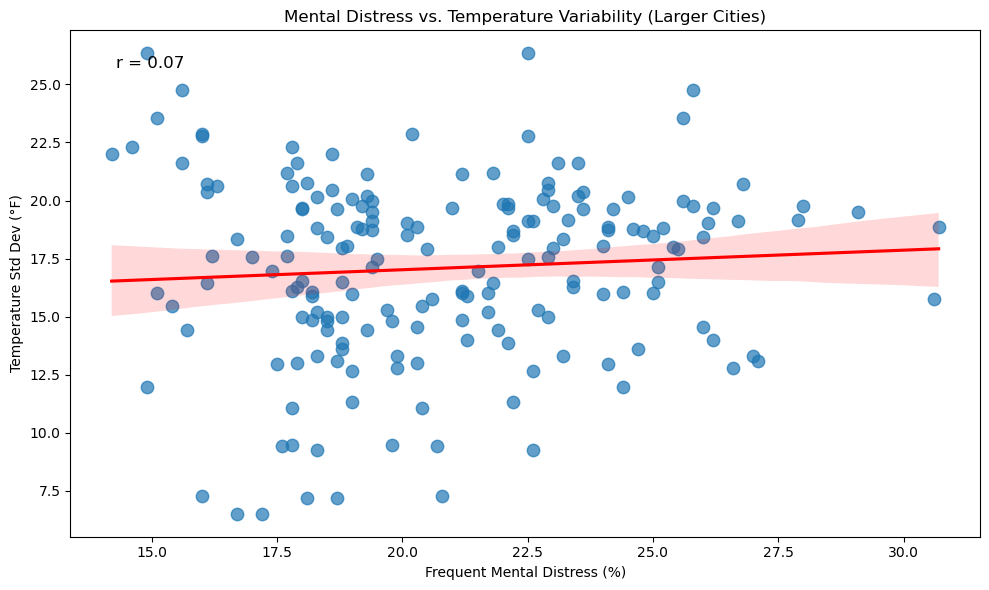

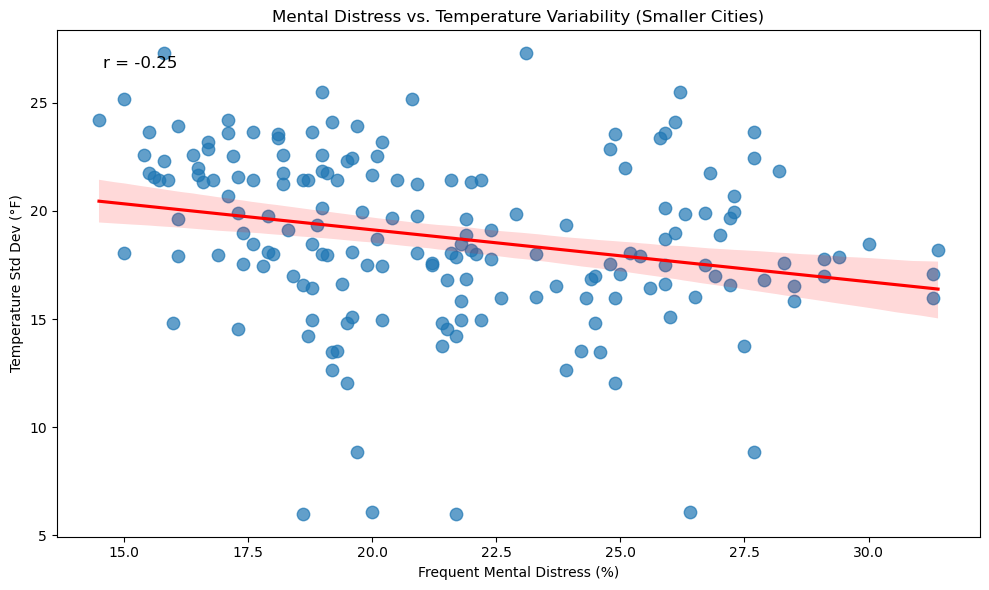

In [53]:
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate median population
median_pop = combined_df['population'].median()

# Split into subsets
large_cities = combined_df[combined_df['population'] >= median_pop]
small_cities = combined_df[combined_df['population'] < median_pop]

# Drop NaNs and compute Pearson r for large cities
valid_large = large_cities[['mental distress %', 'std dev temp']].dropna()
r_large, _ = pearsonr(valid_large['mental distress %'], valid_large['std dev temp'])

# Plot large cities
plt.figure(figsize=(10, 6))
sns.regplot(
    data=large_cities,
    x='mental distress %',
    y='std dev temp',
    scatter_kws={'s': 80, 'alpha': 0.7},
    line_kws={'color': 'red'},
)
plt.text(
    0.05, 0.95,
    f'r = {r_large:.2f}',
    transform=plt.gca().transAxes,
    fontsize=12,
    verticalalignment='top'
)
plt.title('Mental Distress vs. Temperature Variability (Larger Cities)')
plt.xlabel('Frequent Mental Distress (%)')
plt.ylabel('Temperature Std Dev (°F)')
plt.tight_layout()
plt.show()

# Drop NaNs and compute Pearson r for small cities
valid_small = small_cities[['mental distress %', 'std dev temp']].dropna()
r_small, _ = pearsonr(valid_small['mental distress %'], valid_small['std dev temp'])

# Plot small cities
plt.figure(figsize=(10, 6))
sns.regplot(
    data=small_cities,
    x='mental distress %',
    y='std dev temp',
    scatter_kws={'s': 80, 'alpha': 0.7},
    line_kws={'color': 'red'},
)
plt.text(
    0.05, 0.95,
    f'r = {r_small:.2f}',
    transform=plt.gca().transAxes,
    fontsize=12,
    verticalalignment='top'
)
plt.title('Mental Distress vs. Temperature Variability (Smaller Cities)')
plt.xlabel('Frequent Mental Distress (%)')
plt.ylabel('Temperature Std Dev (°F)')
plt.tight_layout()
plt.show()

### Interpretation:
To better understand how temperature variability might relate to mental distress, we visualized this relationship separately for larger and smaller cities, using the median population as a dividing line.

#### Larger Cities (r=0.07)
In larger cities, the correlation between temperature standard deviation and frequent mental distress is slightly positive but very weak (r = 0.07). This near-zero relationship suggests little to no meaningful connection between how much the weather fluctuates and reported mental distress in large urban areas.

However, if we take this small positive trend at face value, one potential explanation could be that greater weather variability in urban environments adds to existing stressors—such as noise, pollution, or overcrowding—which might slightly exacerbate mental strain. That said, the effect is likely minimal and not statistically or practically significant.

#### Smaller Cities (r=-0.25)
In smaller cities, we observe a modest negative correlation (r = -0.25), suggesting that as temperature variability increases, the reported percentage of frequent mental distress tends to decrease. While this is still a weak correlation, it is noticeably stronger than in large cities and in the opposite direction.

One possible interpretation is that in smaller communities, people may be more adaptive to weather fluctuations due to closer ties to the environment or a stronger sense of community support. Alternatively, regions with naturally fluctuating weather patterns might also enjoy other lifestyle or environmental factors, like green space, reduced urban stress, or more active outdoor lifestyles, that buffer against mental distress.

## 4 - Exploring Nonlinear Trends: Mental Distress v. Temperature Variability (Polynomial Fit)

This visualization examines whether the relationship between temperature variability and frequent mental distress may follow a nonlinear pattern, rather than a simple linear correlation. By fitting a second-order polynomial regression, we aim to capture any curved trends that could better explain how weather fluctuations might influence mental health.

**Steps:**
1. Dropped rows where there were missing values
2. Use sns.lmplot() to fit a quadratic regression line 



/var/folders/p2/9fszjsdn5yx_pn2c1brj7kfc0000gn/T/ipykernel_17733/3622710319.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered['mental distress %'] = pd.to_numeric(filtered['mental distress %'], errors='coerce')


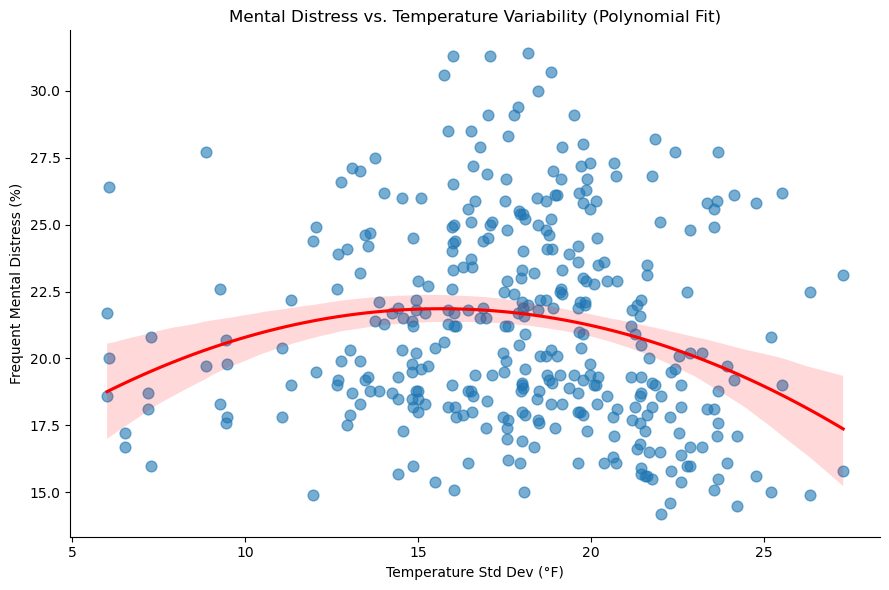

In [ ]:

# Drop missing values
filtered = combined_df.dropna(subset=['std dev temp', 'mental distress %'])
filtered['mental distress %'] = pd.to_numeric(filtered['mental distress %'], errors='coerce')

# Plot using polynomial regression (order=2)
sns.lmplot(
    data=filtered,
    x='std dev temp',
    y='mental distress %',
    order=2,
    scatter_kws={'s': 60, 'alpha': 0.6},
    line_kws={'color': 'red'},
    height=6,
    aspect=1.5
)

plt.title('Mental Distress vs. Temperature Variability (Polynomial Fit)')
plt.xlabel('Temperature Std Dev (°F)')
plt.ylabel('Frequent Mental Distress (%)')
plt.tight_layout()
plt.show()

## Interpretation

The resulting curve reveals a nonlinear, concave (inverted U-shaped) relationship:
- At lower levels of temperature variability (5–15°F), an increase in variability appears to be associated with higher levels of mental distress
- At moderate to higher levels (15–25°F), this trend reverses, and higher temperature variability appears to be associated with lower distress.

This suggests that the connection between weather instability and mental health is not straightforward. Mild variability might be disruptive, neither predictable nor extreme enough to mentally prepare for, which could elevate stress. Higher variability might occur in regions with coping infrastructure (e.g., HVAC, community preparedness) or climates that offer environmental or psychological benefits, mitigating distress.

The strength of this trend is modest, and more detailed analyses like income, geography, and healthcare access would be needed to draw stronger conclusions.

### 5 - Avg Mental Distress by Mean Temperature (Binned Midpoints)

This visualization plots the average percentage of frequent mental distress against mean daily temperature. A linear line of best fit and correlation coefficient are included to assess the direction and strength of the relationship.

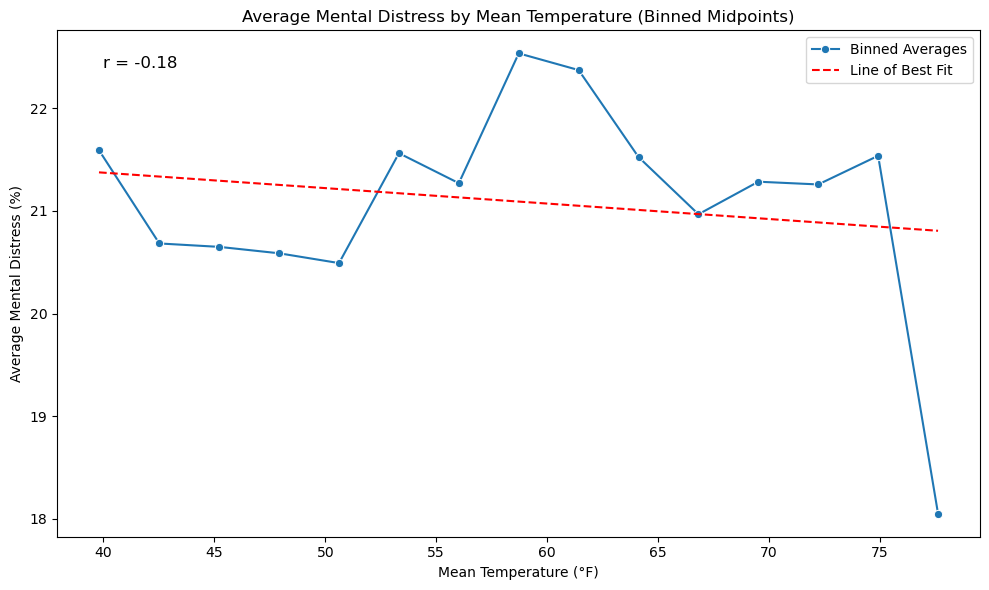

In [65]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

# Create temperature bins
combined_df['temp_bin'] = pd.cut(combined_df['mean temp'], bins=15)

# Group and calculate averages
bin_avg = combined_df.groupby('temp_bin', observed=True)['mental distress %'].mean().reset_index()

# Add numeric midpoints for plotting
bin_avg['temp_bin_mid'] = bin_avg['temp_bin'].apply(lambda x: x.mid)

# Extract x and y
x = bin_avg['temp_bin_mid']
y = bin_avg['mental distress %']

# Compute Pearson correlation coefficient
r, _ = pearsonr(x, y)

# Fit linear regression line (you can change deg=2 for polynomial)
coeffs = np.polyfit(x, y, deg=1)
poly_eq = np.poly1d(coeffs)
x_fit = np.linspace(x.min(), x.max(), 100)
y_fit = poly_eq(x_fit)

# Plot
plt.figure(figsize=(10, 6))
sns.lineplot(data=bin_avg, x='temp_bin_mid', y='mental distress %', marker='o', label='Binned Averages')
plt.plot(x_fit, y_fit, color='red', linestyle='--', label='Line of Best Fit')

# Annotate with correlation coefficient
plt.text(0.05, 0.95, f'r = {r:.2f}', transform=plt.gca().transAxes, fontsize=12, verticalalignment='top')

plt.title('Average Mental Distress by Mean Temperature (Binned Midpoints)')
plt.xlabel('Mean Temperature (°F)')
plt.ylabel('Average Mental Distress (%)')
plt.legend()
plt.tight_layout()
plt.show()

## Interpretation

- The overall trend line is slightly negative, suggesting a weak inverse correlation between mean temperature and mental distress. However, with r = -0.18, this relationship is very weak, and the line is nearly flat—indicating that mean temperature is likely not a strong predictor of mental distress.
- The visual spread of the points fluctuates up and down, further underscoring the lack of a clear directional trend. This behavior between bins suggests that the variation in mental distress may be more influenced by factors other than just temperature.
- One striking outlier appears near the 75–80°F range, where average mental distress drops to its lowest level across all bins. This may be due to:
    1. Geographic regions in this range that are typically warmer year-round (e.g., coastal or tropical cities) and may offer more stable climates or outdoor-lifestyle benefits.
    2. Selection bias or data sparsity in that bin, if few cities fall into this temperature range, a single low, distress value could disproportionately pull the average down.

## 6 - Predicting 2022 Mental Distress Using 2021 Weather Data

We build a linear regression model to predict rates of mental distress in 2022 based on prior year’s (2021) weather patterns.

r^2 score:  0.012610680195059065


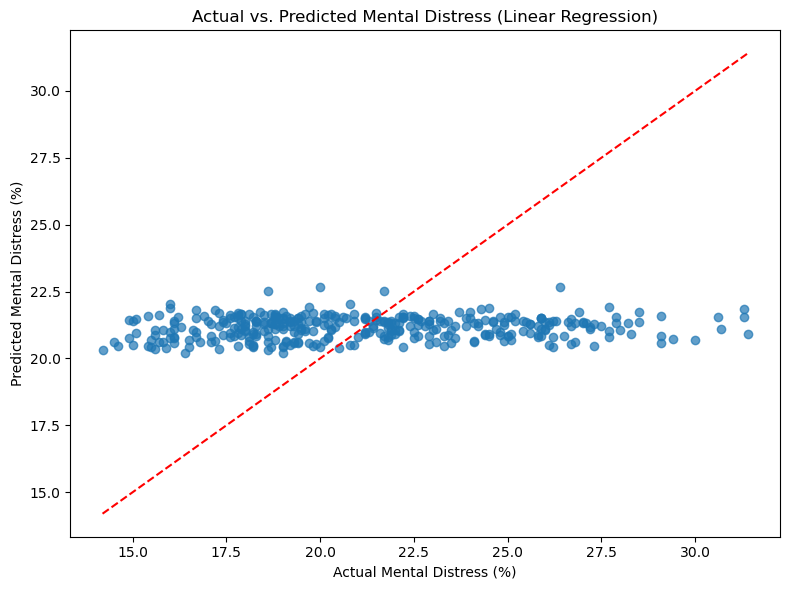

In [73]:
from sklearn.linear_model import LinearRegression
# --- Prepare data for regression: Predict 2022 mental distress using 2021 weather ---
# Filter for 2021 weather and 2022 mental health
weather_2021 = weather_summary[weather_summary['year'] == 2021]
mental_2022 = mental_health_data[mental_health_data['year'] == 2022]

# Merge on location
regression_df = pd.merge(
    weather_2021[['location', 'mean temp', 'std dev temp', 'range temp']],
    mental_2022[['location', 'mental distress %']],
    on='location',
    how='inner'
)

# Drop missing values and ensure numeric
regression_df = regression_df.dropna(subset=['mean temp', 'std dev temp', 'range temp', 'mental distress %'])
regression_df['mental distress %'] = pd.to_numeric(regression_df['mental distress %'], errors='coerce')
regression_df = regression_df.dropna(subset=['mental distress %'])

# Define features and target
X = regression_df[['mean temp', 'std dev temp', 'range temp']]
y = regression_df['mental distress %']

# Fit linear regression
reg = LinearRegression()
reg.fit(X, y)
y_pred = reg.predict(X)

# Compute R^2 score
r2 = reg.score(X,y)
print("r^2 score: ", r2)

# --- Plot: Actual vs. Predicted Mental Distress ---
plt.figure(figsize=(8, 6))
plt.scatter(y, y_pred, alpha=0.7)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')  # ideal prediction line
plt.xlabel('Actual Mental Distress (%)')
plt.ylabel('Predicted Mental Distress (%)')
plt.title('Actual vs. Predicted Mental Distress (Linear Regression)')
plt.tight_layout()
plt.show()

### Interpretation of Linear Regression (2021 Weather Predicting 2022 Mental Health)

In this analysis, a linear regression model is trained to examine whether weather patterns from 2021 (mean temperature, temperature standard deviation, and temperature range) could predict the rate of frequent mental distress in 2022.

**Key Findings:**

- The **R² score** of the model is **0.0126**, meaning the weather metrics explain only about **1.3%** of the variation in mental distress across cities.
- The **mean squared error (MSE)** is relatively high, further indicating poor prediction accuracy.
- The **scatterplot** shows that predicted values do not align closely with actual mental distress rates, reinforcing the model's weak predictive power.

**Interpretation:**

The results suggest that while weather might have some influence on mental health, it is not a strong sole predictor in this dataset. Mental distress is likely driven by a complex set of factors such as economic, social, and healthcare-related variables which are not represented in this model. Additionally, the relatively small dataset (limited number of cities with both 2021 weather and 2022 mental health data) could also impact the model’s ability to generalize. It is also worth noting that there is a right-side outlier that affects the regression line and R² score.

# Ethics & Privacy

Using publicly available datasets, our project explores the relationship between seasonal temperature variability and mental health outcomes. Given the use of sensitive health information, it is crucial to uphold ethical standards at every stage, from posing the research question to interpreting and sharing our findings.

We acknowledge that mental health is a personal and stigmatized topic. If not approached carefully, our analysis could unintentionally lead to misinterpretations and/or harmful stereotypes. We used datasets from credible public sources. Both the CDC mental health data and the Carnegie Mellon Temperature and Precipitation Data are publicly available to download, with no identifiable personal data. Our weather data is aggregated at the city level and does not contain personally identifiable information, however, it is important to understand that mental health data patterns are shaped by complex social and economic inequalities. In addition, the weather data is based on models and may not include small differences in temperature that people experience. For example, the way shade or buildings can affect how cold or hot it feels in different areas. For this reason, we avoided directly comparing cities and ranking them in terms of being “happier” or “more stable”. Instead, our analysis is framed as an exploration of how environmental factors may affect mental health trends across the United States.

The mental health metrics we use (depression and frequent mental distress) are estimated using a statistical model technique called multilevel regression and poststratification, based on large datasets including the CDC’s Behavioral Risk Factor Surveillance System and U.S. Census data. We recognize that these model-based estimates provide helpful information at the city level, but they are not direct individual-level responses. The dataset does not raise any privacy concerns, however, there are ethical considerations that must be addressed.

The estimates for the CDC mental health data apply only to adults (18 and over), which means that mental health experiences among younger populations are not represented. This introduces bias in cities with a larger youth population. Additionally, the BRFSS is based on survey responses; it is possible that the data gathered may have underrepresented marginalized populations, some individuals unable to submit the survey due to accessibility, language barriers, or disclosure of mental health. Individuals with reliable internet access, literacy skills, and the patience for long surveys are more likely to participate, introducing potential bias. 

We are aware as a group that if not carefully addressed, these factors could lead to skewed interpretations and inaccuracy in our findings. To mitigate these potential biases, we will read through the documentation for both datasets before fully identifying known limitations in data collection, such as underrepresented regions or demographic groups, and also to get a comprehensive understanding of our datasets. We will also assess how surveys were conducted and note any missing data in both datasets (climate records and mental health), especially from less-monitored regions. During our analysis, we will be transparent about how the data is modeled and avoid implying causality. 

We acknowledge that combining weather and mental health data could potentially lead to overgeneralized conclusions. Thus, we will use respectful language around mental health while presenting our findings. Our goal is to responsibly explore how the environment may influence well-being outcomes, without reinforcing stereotypes or spreading misinformation.


# Discussion and Conclusion

Our findings when matching CDC mental health metrics from 2021 and 2022 to weather data indicate that temperature variability, measured by standard deviation, range, or mean temperature, contributes minimally to explaining variation in mental distress among cities. The correlation coefficients between mental distress and temperature metrics were low. Additionally, regression models we used provided poor predictive accuracy. While prior studies have stated that overall temperature and climate trends relate to happiness, our work narrowed the scope to short-term variability. The stability and instability of daily temperatures have little to no relationship to the menta well-being at the city-level. 
Instead, other variables such as economic, social, healthcare access, and etc play a more substantial role in shaping mental health outcomes than temperature variability alone. Despite the negative trend, the relationship between mean temperature and mental distress is too week to draw significant conclusions. Some limitations include the inability to control for variables such as economic inequality and healthcare access. Our work demonstrations that while enviornmental conditions like weather may contribute to well-being, mental health is a multidimensional ussue with multiple determinants.


# Team Contributions

* Thatcher Eames: New Data Sets, Data Analysis
* Katie Ngo: Making sure notebook flows 
* Preity Singh: Data Analysis
* Lavin Ma: Data Wrangling
* Krrish Jain: Conclusion